# 🛒 Retail Sales Analysis — Data Cleaning + EDA (Python)

**Goal:** Clean a messy sales dataset, then extract business insights from it.

**Flow (the standard flow of every data analyst project):**
1. Load and understand the data
2. Data cleaning (duplicates, missing values, inconsistent text, outliers)
3. Feature engineering (creating new useful columns)
4. EDA — charts + insights
5. Conclusion

**Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`

In [3]:
# import python libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

os.makedirs("outputs", exist_ok=True)
os.makedirs("data", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"outputs/{name}.png", dpi=130)
    plt.show()
    plt.close("all") 

## 1️⃣ Load and Understand the Data

In [5]:
df = pd.read_csv("raw_sales_data.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2060, 12)


,order_id,order_date,customer_name,city,category,product,unit_price,quantity,discount_pct,payment_mode,delivery_days,rating
0,ORD101706,2024-04-24,Rahul Wankhade,Chennai,Sports,Dumbbell Set,1778.76,3,5.0,UPI,7,4.0
1,ORD100110,2024-07-24,Aditya Iyer,NAGPUR,Clothing,Jeans,1650.54,1,5.0,Credit Card,2,3.0
2,ORD101464,2024-09-19,Amit Khan,mumbai,Sports,Cricket Bat,2617.34,5,15.0,Debit Card,8,4.0
3,ORD100196,2024-07-31,Aarav Sharma,MUMBAI,Clothing,Jacket,3384.46,2,0.0,UPI,7,5.0
4,ORD100572,2025-06-17,Neha Khan,Pune,Clothing,Jeans,1852.27,3,5.0,Debit Card,4,3.0


In [7]:
# Column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2060 entries, 0 to 2059
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       2060 non-null   object 
 1   order_date     2060 non-null   object 
 2   customer_name  2060 non-null   object 
 3   city           1994 non-null   object 
 4   category       2060 non-null   object 
 5   product        2060 non-null   object 
 6   unit_price     2060 non-null   float64
 7   quantity       2060 non-null   int64  
 8   discount_pct   1988 non-null   float64
 9   payment_mode   2060 non-null   object 
 10  delivery_days  2060 non-null   int64  
 11  rating         1931 non-null   float64
dtypes: float64(3), int64(2), object(7)
memory usage: 193.3+ KB


In [9]:
# Quick statistical summary of numeric columns
df.describe()

,unit_price,quantity,discount_pct,delivery_days,rating
count,2060.000000,2060.000000,1988.000000,2060.000000,1931.000000
mean,1408.610922,3.008252,6.903924,4.602913,3.877266
std,979.163634,21.959374,6.442368,2.306439,1.149884
min,162.130000,1.000000,0.000000,-3.000000,1.000000
25%,646.165000,1.000000,0.000000,3.000000,3.000000
50%,1083.120000,2.000000,5.000000,5.000000,4.000000
75%,2057.497500,3.000000,10.000000,7.000000,5.000000
max,3848.380000,500.000000,20.000000,8.000000,5.000000


In [11]:
# How many missing values does each column have?
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())

city             66
discount_pct     72
rating          129
dtype: int64

Duplicate rows: 60


In [13]:
# Look at the unique values in the city column -> the spelling mess will be obvious
print(sorted(df["city"].dropna().unique()))

['AMRAVATI', 'Amravati', 'Amravati ', 'BENGALURU', 'Bangalore', 'Bengaluru', 'Bengaluru ', 'CHENNAI', 'Chennai', 'Chennai ', 'DELHI', 'Delhi', 'Delhi ', 'HYDERABAD', 'Hyderabad', 'Hyderabad ', 'JAIPUR', 'Jaipur', 'Jaipur ', 'KOLKATA', 'Kolkata', 'Kolkata ', 'MUMBAI', 'Mumbai', 'Mumbai ', 'NAGPUR', 'Nagpur', 'Nagpur ', 'PUNE', 'Pune', 'Pune ', 'amravati', 'bengaluru', 'chennai', 'delhi', 'hyderabad', 'jaipur', 'kolkata', 'mumbai', 'nagpur', 'pune']


## 2️⃣ Data Cleaning


In [19]:
clean = df.copy()
rows_before = len(clean)

# --- Step 1: Remove duplicates ---
clean = clean.drop_duplicates()
print(f"Duplicates removed: {rows_before - len(clean)}")

Duplicates removed: 60


In [21]:
# --- Step 2: Standardize the city text ---
# strip()  -> remove extra leading/trailing spaces
# title()  -> 'mumbai' / 'MUMBAI' -> 'Mumbai'

clean["city"] = clean["city"].str.strip().str.title()

# Bangalore and Bengaluru are the same city
clean["city"] = clean["city"].replace({"Bangalore": "Bengaluru"})

# Turn missing cities into 'Unknown' (we won't delete the rows, the rest of the info is useful)
clean["city"] = clean["city"].fillna("Unknown")
print(sorted(clean["city"].unique()))

['Amravati', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai', 'Nagpur', 'Pune', 'Unknown']


In [23]:
# --- Step 3: Convert the date column to a proper datetime type ---
# Dates came in two formats: 2024-04-24 and 24/04/2024. We parse each separately and combine them.

d1 = pd.to_datetime(clean["order_date"], format="%Y-%m-%d", errors="coerce")
d2 = pd.to_datetime(clean["order_date"], format="%d/%m/%Y", errors="coerce")
clean["order_date"] = d1.fillna(d2)
print("Unparsed dates:", clean["order_date"].isnull().sum())

Unparsed dates: 0


In [25]:
# --- Step 4: Handle missing values ---
# Missing discount_pct -> assume no discount was given (0)

clean["discount_pct"] = clean["discount_pct"].fillna(0)

# Missing rating -> we will NOT fill it. Inventing ratings would distort the analysis.
# Pandas mean() / median() ignore NaN automatically.

print("Missing ratings (left on purpose):", clean["rating"].isnull().sum())

Missing ratings (left on purpose): 126


In [27]:
# --- Step 5: Remove outliers ---
# A quantity of 1-5 is normal, 500 is a bad entry. delivery_days can never be negative.
print("Outlier quantity rows:", (clean["quantity"] > 10).sum())
print("Invalid delivery_days rows (< 1):", (clean["delivery_days"] < 1).sum())

# .copy() avoids pandas' SettingWithCopyWarning on the assignment below
clean = clean[(clean["quantity"] <= 10) & (clean["delivery_days"] >= 1)].copy()

# Now we can safely convert quantity to an integer
clean["quantity"] = clean["quantity"].astype(int)

Outlier quantity rows: 4
Invalid delivery_days rows (< 1): 4


In [29]:
# Health check after cleaning
clean = clean.reset_index(drop=True)
print(f"Rows: {rows_before}  ->  {len(clean)}")
print("Missing values left:\n", clean.isnull().sum()[clean.isnull().sum() > 0])

Rows: 2060  ->  1992
Missing values left:
 rating    126
dtype: int64


## 3️⃣ Feature Engineering


In [32]:
# Revenue = price x quantity, then minus the discount
clean["gross_amount"] = clean["unit_price"] * clean["quantity"]
clean["revenue"] = (clean["gross_amount"] * (1 - clean["discount_pct"] / 100)).round(2)

# Different parts of the date
clean["year"] = clean["order_date"].dt.year
clean["month"] = clean["order_date"].dt.month
clean["month_name"] = clean["order_date"].dt.month_name()
clean["weekday"] = clean["order_date"].dt.day_name()
clean["year_month"] = clean["order_date"].dt.to_period("M").astype(str)

clean.to_csv("data/cleaned_sales_data.csv", index=False)
clean.head()

,order_id,order_date,customer_name,city,category,product,unit_price,quantity,discount_pct,payment_mode,delivery_days,rating,gross_amount,revenue,year,month,month_name,weekday,year_month
0,ORD101706,2024-04-24,Rahul Wankhade,Chennai,Sports,Dumbbell Set,1778.76,3,5.0,UPI,7,4.0,5336.28,5069.47,2024,4,April,Wednesday,2024-04
1,ORD100110,2024-07-24,Aditya Iyer,Nagpur,Clothing,Jeans,1650.54,1,5.0,Credit Card,2,3.0,1650.54,1568.01,2024,7,July,Wednesday,2024-07
2,ORD101464,2024-09-19,Amit Khan,Mumbai,Sports,Cricket Bat,2617.34,5,15.0,Debit Card,8,4.0,13086.70,11123.70,2024,9,September,Thursday,2024-09
3,ORD100196,2024-07-31,Aarav Sharma,Mumbai,Clothing,Jacket,3384.46,2,0.0,UPI,7,5.0,6768.92,6768.92,2024,7,July,Wednesday,2024-07
4,ORD100572,2025-06-17,Neha Khan,Pune,Clothing,Jeans,1852.27,3,5.0,Debit Card,4,3.0,5556.81,5278.97,2025,6,June,Tuesday,2025-06


## 4️⃣ Exploratory Data Analysis (EDA)
### 📌 KPIs (headline numbers)

In [35]:
total_revenue = clean["revenue"].sum()
total_orders = clean["order_id"].nunique()
aov = total_revenue / total_orders           # Average Order Value
avg_rating = clean["rating"].mean()

print(f"Total Revenue       : ₹{total_revenue:,.0f}")
print(f"Total Orders        : {total_orders:,}")
print(f"Avg Order Value     : ₹{aov:,.0f}")
print(f"Average Rating      : {avg_rating:.2f} / 5")
print(f"Avg Delivery (days) : {clean['delivery_days'].mean():.1f}")

Total Revenue       : ₹5,353,231
Total Orders        : 1,992
Avg Order Value     : ₹2,687
Average Rating      : 3.88 / 5
Avg Delivery (days) : 4.6


### Q1. Which category brings in the most revenue?

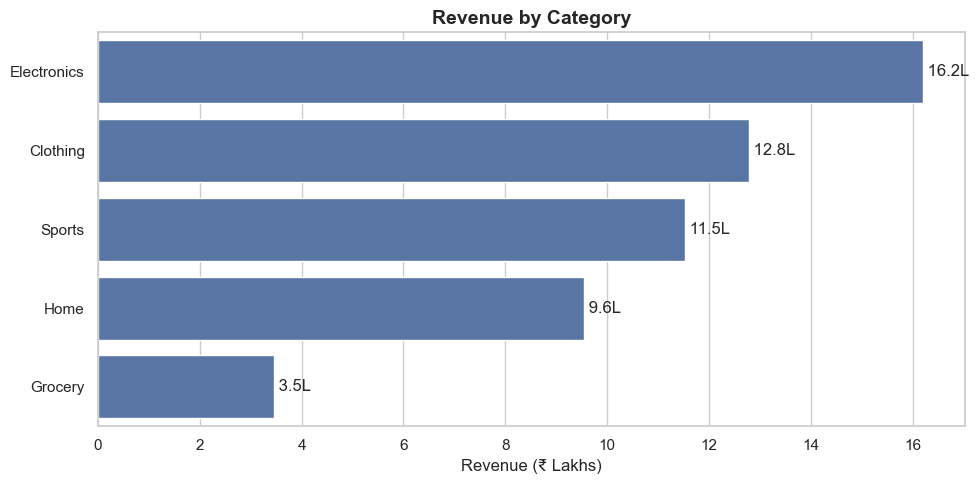

In [38]:
cat_rev = clean.groupby("category")["revenue"].sum().sort_values(ascending=False)

ax = sns.barplot(x=cat_rev.values / 1e5, y=cat_rev.index, color="#4C72B0")
ax.set_title("Revenue by Category")
ax.set_xlabel("Revenue (₹ Lakhs)")
ax.set_ylabel("")
for i, v in enumerate(cat_rev.values / 1e5):
    ax.text(v, i, f" {v:.1f}L", va="center")
save("01_revenue_by_category")

### Q2. What does the monthly sales trend look like?

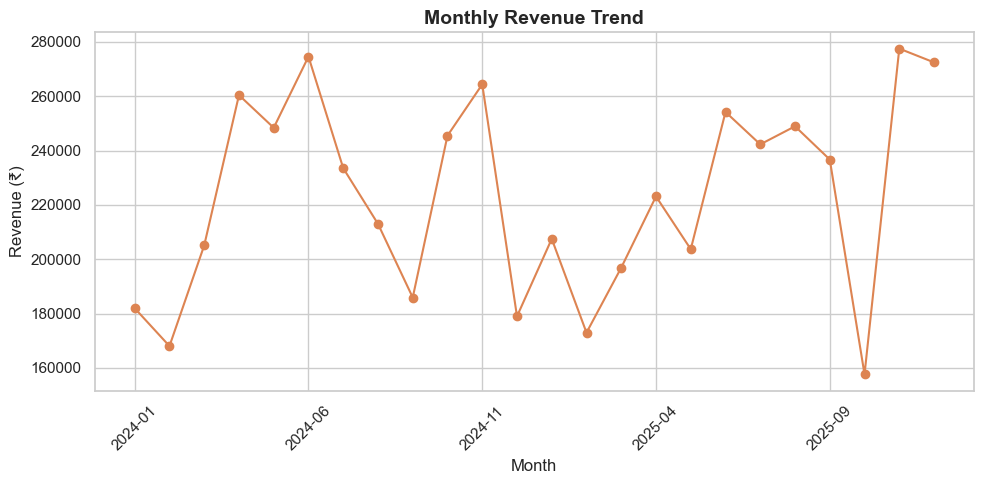

Best month: 2025-11  (₹277,515)


In [41]:
monthly = clean.groupby("year_month")["revenue"].sum()

ax = monthly.plot(marker="o", color="#DD8452")
ax.set_title("Monthly Revenue Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (₹)")
plt.xticks(rotation=45)
save("02_monthly_revenue_trend")

best = monthly.idxmax()
print(f"Best month: {best}  (₹{monthly.max():,.0f})")

### Q3. Which are the top 10 products?

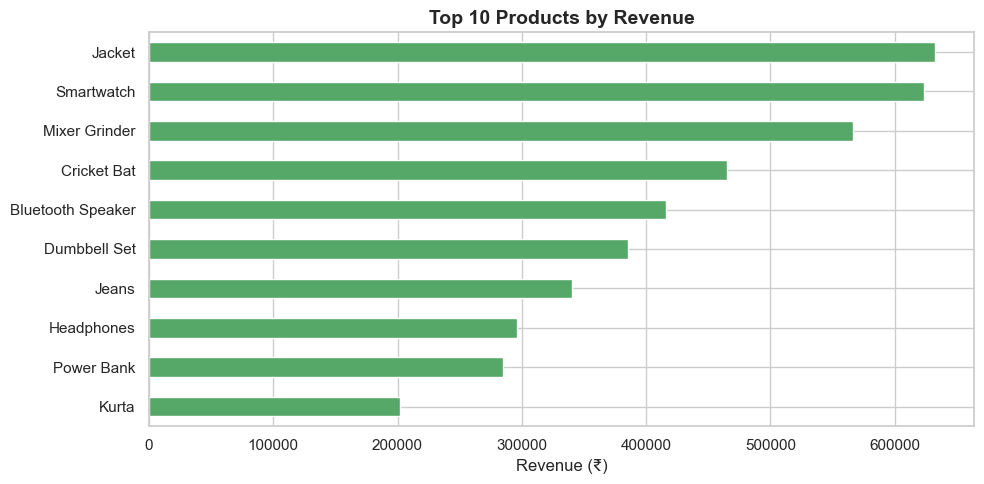

In [44]:
top_products = clean.groupby("product")["revenue"].sum().nlargest(10).sort_values()

ax = top_products.plot(kind="barh", color="#55A868")
ax.set_title("Top 10 Products by Revenue")
ax.set_xlabel("Revenue (₹)")
ax.set_ylabel("")
save("03_top_products")

### Q4. Which city places the most orders?

Text(0, 0.5, '')

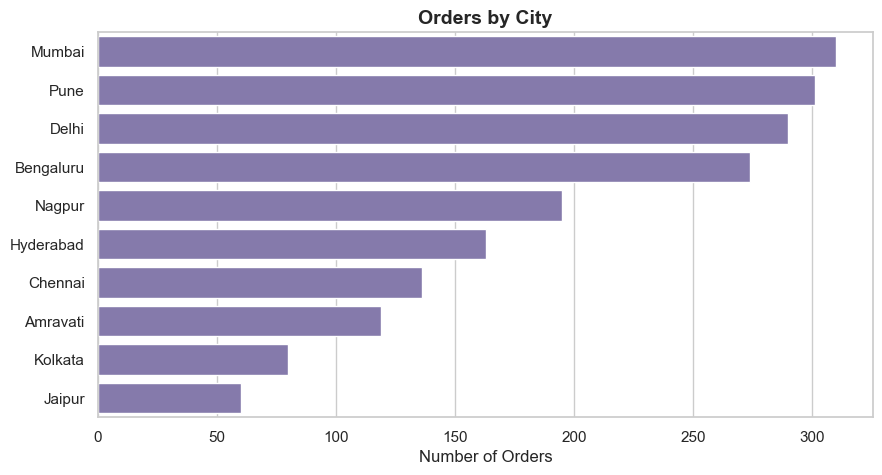

In [47]:
city_orders = clean[clean["city"] != "Unknown"]["city"].value_counts()

ax = sns.barplot(x=city_orders.values, y=city_orders.index, color="#8172B3")
ax.set_title("Orders by City")
ax.set_xlabel("Number of Orders")
ax.set_ylabel("")

### Q5. How do people pay?

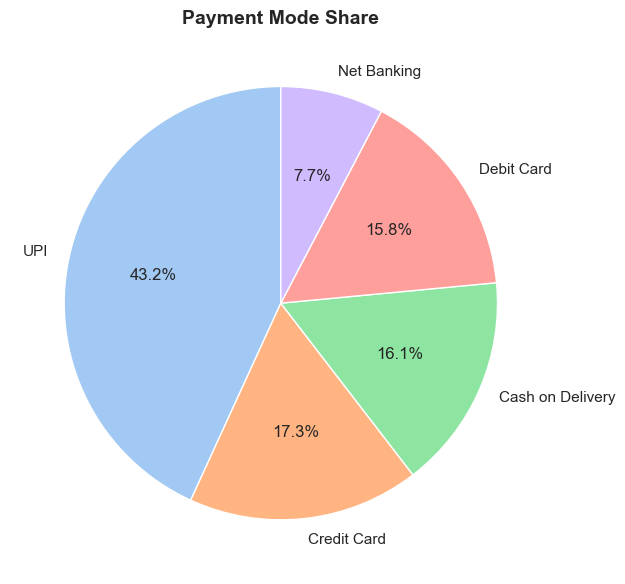

In [50]:
pay = clean["payment_mode"].value_counts()

plt.figure(figsize=(9, 6))
plt.pie(pay.values, labels=pay.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("pastel"), wedgeprops={"edgecolor": "white"})
plt.title("Payment Mode Share")
save("05_payment_modes")

### Q6. What does the customer rating distribution look like?

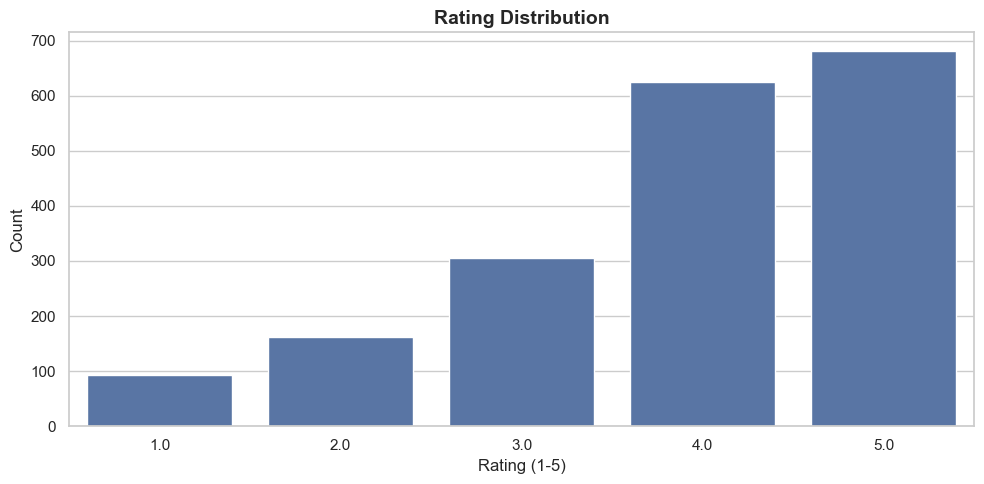

In [53]:
ax = sns.countplot(x="rating", data=clean, color="#4C72B0")
ax.set_title("Rating Distribution")
ax.set_xlabel("Rating (1-5)")
ax.set_ylabel("Count")
save("06_rating_distribution")

### Q7. Does late delivery lower the rating?

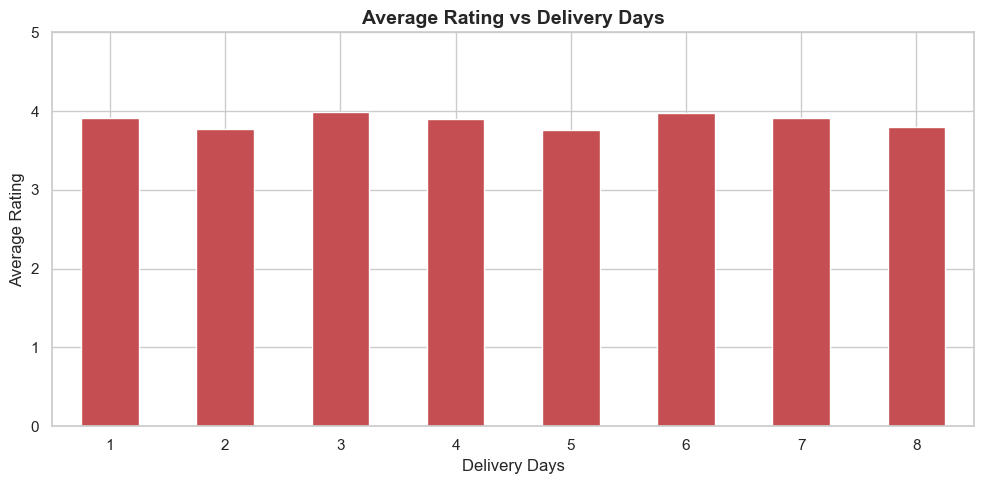

In [56]:
rating_by_delivery = clean.groupby("delivery_days")["rating"].mean()

ax = rating_by_delivery.plot(kind="bar", color="#C44E52")
ax.set_title("Average Rating vs Delivery Days")
ax.set_xlabel("Delivery Days")
ax.set_ylabel("Average Rating")
ax.set_ylim(0, 5)
plt.xticks(rotation=0)
save("07_rating_vs_delivery")

### Q8. Category x Month heatmap — what sells more, and when?

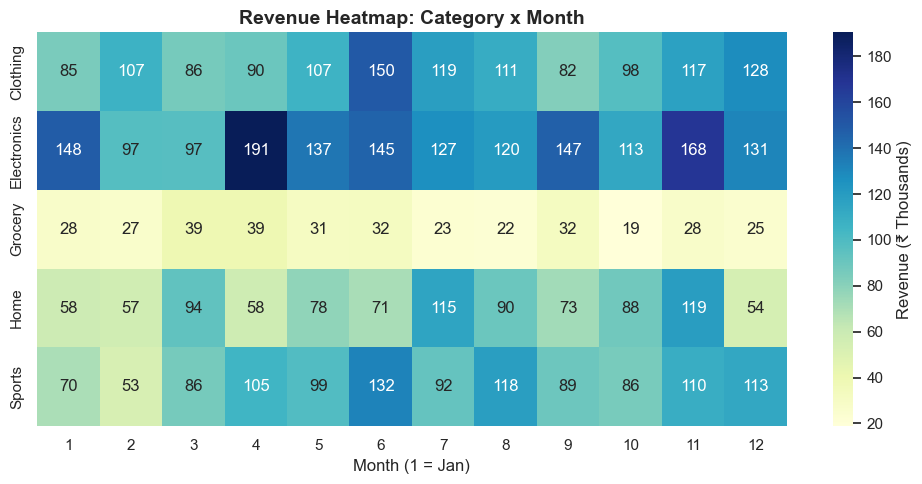

In [59]:
pivot = clean.pivot_table(values="revenue", index="category", columns="month", aggfunc="sum") / 1e3

ax = sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Revenue (₹ Thousands)"})
ax.set_title("Revenue Heatmap: Category x Month")
ax.set_xlabel("Month (1 = Jan)")
ax.set_ylabel("")
save("08_category_month_heatmap")

### Q9. Relationships between numeric columns (Correlation)

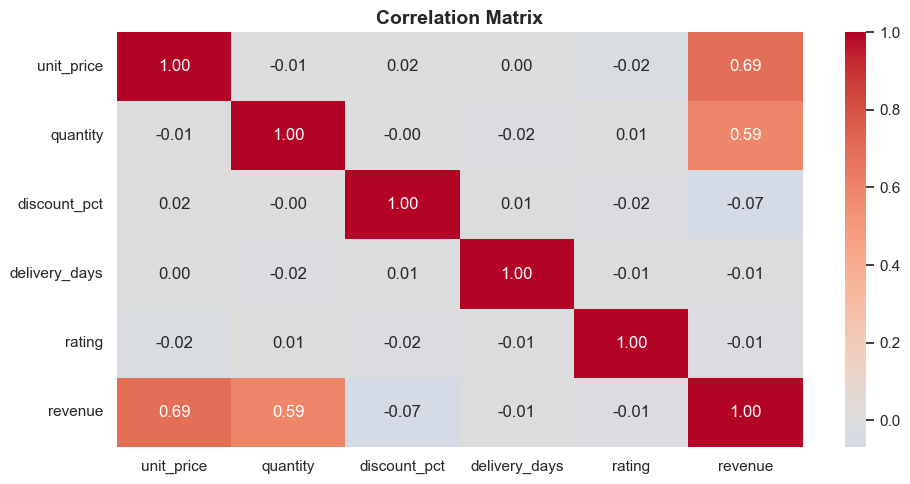

In [62]:
num_cols = ["unit_price", "quantity", "discount_pct", "delivery_days", "rating", "revenue"]
ax = sns.heatmap(clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
ax.set_title("Correlation Matrix")
save("09_correlation")

### Q10. Does a bigger discount lead to higher quantity sold?

discount_pct
0.0     2.03
5.0     2.15
10.0    1.98
15.0    2.12
20.0    2.01
Name: quantity, dtype: float64


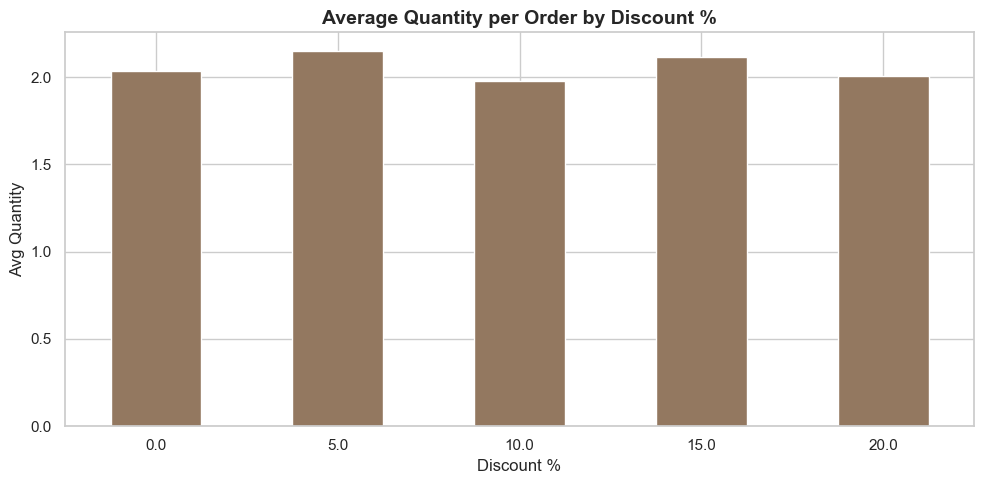

In [65]:
disc = clean.groupby("discount_pct")["quantity"].mean()
print(disc.round(2))

ax = disc.plot(kind="bar", color="#937860")
ax.set_title("Average Quantity per Order by Discount %")
ax.set_xlabel("Discount %")
ax.set_ylabel("Avg Quantity")
plt.xticks(rotation=0)
save("10_discount_vs_quantity")

## 5️⃣ Key Insights & Conclusion

In [68]:
top_cat = cat_rev.idxmax()
top_city = city_orders.idxmax()
top_pay = pay.idxmax()

weekday_rev = clean.groupby("weekday")["revenue"].sum().idxmax()
best = clean.groupby("month")["revenue"].sum().idxmax()

print("=" * 55)
print("KEY INSIGHTS")
print("=" * 55)

print(f"1. Top category          : {top_cat} (₹{cat_rev.max():,.0f})")
print(f"2. Top city (orders)     : {top_city} ({city_orders.max()} orders)")
print(f"3. Most used payment     : {top_pay} ({pay.max() / pay.sum():.0%})")
print(f"4. Best revenue month    : {best}")
print(f"5. Best revenue weekday  : {weekday_rev}")
print(f"6. Avg order value       : ₹{aov:,.0f}")
print(f"7. Avg rating            : {avg_rating:.2f}/5")

KEY INSIGHTS
1. Top category          : Electronics (₹1,621,304)
2. Top city (orders)     : Mumbai (310 orders)
3. Most used payment     : UPI (43%)
4. Best revenue month    : 11
5. Best revenue weekday  : Thursday
6. Avg order value       : ₹2,687
7. Avg rating            : 3.88/5


### ✅ Business Recommendations (example)
- Increase inventory and marketing for the top category.
- Run targeted campaigns in cities with fewer orders.
- UPI is the most popular, so try UPI cashback offers.
- Keep stock ready before the best-performing month.
